# 04 - Modeling: Predicting 30-Day Readmission

**Input:** `../data/cleaned.csv` (69,970 patients, 139 features + target `readmitted_30`, already encoded and scaled)

**Models:** Logistic Regression and Decision Tree

**Workflow:**
1. Load and split into train / test
2. Baseline: what accuracy do we get by always guessing "not readmitted"?
3. Handle class imbalance
4. Train Logistic Regression
5. Train Decision Tree
6. Evaluate: accuracy, precision, recall, ROC-AUC, confusion matrix, ROC curve
7. Top features
8. Save results for the dashboard

## Step 1: Load and Split

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, roc_curve, classification_report)

df = pd.read_csv("../data/cleaned.csv")
print("Shape:", df.shape)

Shape: (69970, 140)


In [2]:
# X = features (everything except the target), y = target
X = df.drop(columns=["readmitted_30"])
y = df["readmitted_30"]

# 80% train, 20% test
# stratify=y keeps the same share of readmitted patients (~9%) in both parts
# random_state=42 makes the split the same every time we run the notebook
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Train:", X_train.shape, "| readmitted %:", round(y_train.mean() * 100, 2))
print("Test: ", X_test.shape, "| readmitted %:", round(y_test.mean() * 100, 2))

Train: (55976, 139) | readmitted %: 8.97
Test:  (13994, 139) | readmitted %: 8.97


## Step 2: Baseline

Only ~9% of patients are readmitted. A "model" that always says **0 (not readmitted)** is already ~91% accurate, but it finds **zero** readmitted patients. Accuracy alone is therefore misleading. **Recall** (how many real readmissions we catch) and **ROC-AUC** (how well the model ranks risky patients above safe ones) matter more.

In [3]:
# predict 0 for every test patient
baseline_pred = np.zeros(len(y_test))

print("Baseline accuracy:", round(accuracy_score(y_test, baseline_pred), 4))
print("Baseline recall:  ", recall_score(y_test, baseline_pred))

Baseline accuracy: 0.9103
Baseline recall:   0.0


## Step 3: Handle Class Imbalance

We use `class_weight="balanced"`. It tells the model that a mistake on a readmitted patient (the rare class) costs about **10 times** more than a mistake on a non-readmitted one. The weight is `total / (2 * class count)`. No rows are added or removed; the model just pays more attention to the rare class.

In [4]:
# the weights that class_weight="balanced" will use
n = len(y_train)
print("Weight for class 0:", round(n / (2 * (y_train == 0).sum()), 3))
print("Weight for class 1:", round(n / (2 * (y_train == 1).sum()), 3))

Weight for class 0: 0.549
Weight for class 1: 5.573


## Step 4: Logistic Regression

In [5]:
# max_iter=1000 gives the solver enough steps to finish with 139 features
log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train, y_train)

# predicted class (0/1) and predicted probability of readmission
log_pred = log_model.predict(X_test)
log_prob = log_model.predict_proba(X_test)[:, 1]

## Step 5: Decision Tree

`max_depth=5` keeps the tree small. A deep tree memorises the training data (overfitting) and is impossible to read.

In [6]:
tree_model = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)
tree_prob = tree_model.predict_proba(X_test)[:, 1]

## Step 6: Evaluate

- **Accuracy:** share of all predictions that are correct
- **Precision:** of the patients we flagged as readmitted, how many really were
- **Recall:** of the patients really readmitted, how many we flagged
- **ROC-AUC:** 0.5 = random guessing, 1.0 = perfect ranking

In [7]:
# one row per model
results = pd.DataFrame({
    "model": ["Logistic Regression", "Decision Tree"],
    "accuracy": [accuracy_score(y_test, log_pred), accuracy_score(y_test, tree_pred)],
    "precision": [precision_score(y_test, log_pred), precision_score(y_test, tree_pred)],
    "recall": [recall_score(y_test, log_pred), recall_score(y_test, tree_pred)],
    "roc_auc": [roc_auc_score(y_test, log_prob), roc_auc_score(y_test, tree_prob)],
})

results.round(4)

,model,accuracy,precision,recall,roc_auc
0,Logistic Regression,0.6581,0.1388,0.5402,0.6457
1,Decision Tree,0.6100,0.1277,0.5745,0.6187


In [8]:
print("Logistic Regression")
print(classification_report(y_test, log_pred, digits=3))
print("Decision Tree")
print(classification_report(y_test, tree_pred, digits=3))

Logistic Regression
              precision    recall  f1-score   support

           0      0.937     0.670     0.781     12739
           1      0.139     0.540     0.221      1255

    accuracy                          0.658     13994
   macro avg      0.538     0.605     0.501     13994
weighted avg      0.865     0.658     0.731     13994

Decision Tree
              precision    recall  f1-score   support

           0      0.936     0.614     0.741     12739
           1      0.128     0.575     0.209      1255

    accuracy                          0.610     13994
   macro avg      0.532     0.594     0.475     13994
weighted avg      0.864     0.610     0.694     13994



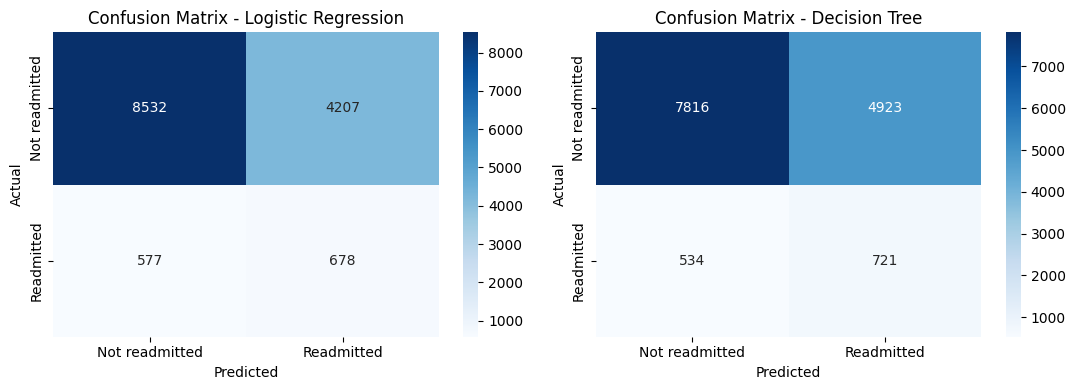

In [9]:
# confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, pred, name in zip(axes, [log_pred, tree_pred], ["Logistic Regression", "Decision Tree"]):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Not readmitted", "Readmitted"], yticklabels=["Not readmitted", "Readmitted"])
    ax.set_title("Confusion Matrix - " + name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

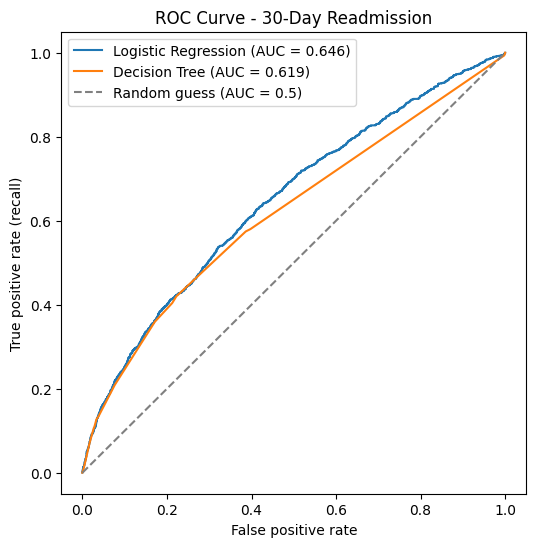

In [10]:
# ROC curve: true positive rate vs false positive rate at every threshold
log_fpr, log_tpr, _ = roc_curve(y_test, log_prob)
tree_fpr, tree_tpr, _ = roc_curve(y_test, tree_prob)

plt.figure(figsize=(6, 6))
plt.plot(log_fpr, log_tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, log_prob):.3f})")
plt.plot(tree_fpr, tree_tpr, label=f"Decision Tree (AUC = {roc_auc_score(y_test, tree_prob):.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guess (AUC = 0.5)")
plt.title("ROC Curve - 30-Day Readmission")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.show()

**What we see:**
- **Logistic Regression is better on every ranking measure:** ROC-AUC 0.646 vs 0.619.
- Both models catch more than half of the real readmissions (recall 0.540 and 0.575), far better than the baseline's 0.
- **Precision is low** (0.139 and 0.128). Only about 1 in 7-8 flagged patients is really readmitted, so many patients get flagged "just in case".
- Accuracy (0.658 and 0.610) is below the baseline's 0.91, because the models now flag many patients to catch the rare readmissions. This is the expected trade-off.
- An AUC around 0.65 is typical for this dataset. Readmission depends on things not recorded here (support at home, follow-up care), so it is hard to predict.

## Step 7: Top Features

### Logistic Regression coefficients
Because the numeric features are scaled, the coefficient size shows importance. **Positive = raises** readmission risk, **negative = lowers** it.

In [11]:
coef = pd.DataFrame({"feature": X.columns, "coefficient": log_model.coef_[0]})
coef["abs_coef"] = coef["coefficient"].abs()

top_log = coef.sort_values("abs_coef", ascending=False).head(10)
top_log[["feature", "coefficient"]].round(3)

,feature,coefficient
105,discharge_disposition_id_15,2.038
115,discharge_disposition_id_28,1.746
53,payer_code_SI,-1.729
23,tolazamide,-1.717
110,discharge_disposition_id_22,1.567
101,admission_type_id_7,-1.446
111,discharge_disposition_id_23,-1.416
118,discharge_disposition_id_5,1.206
104,discharge_disposition_id_12,1.104
122,discharge_disposition_id_9,0.756


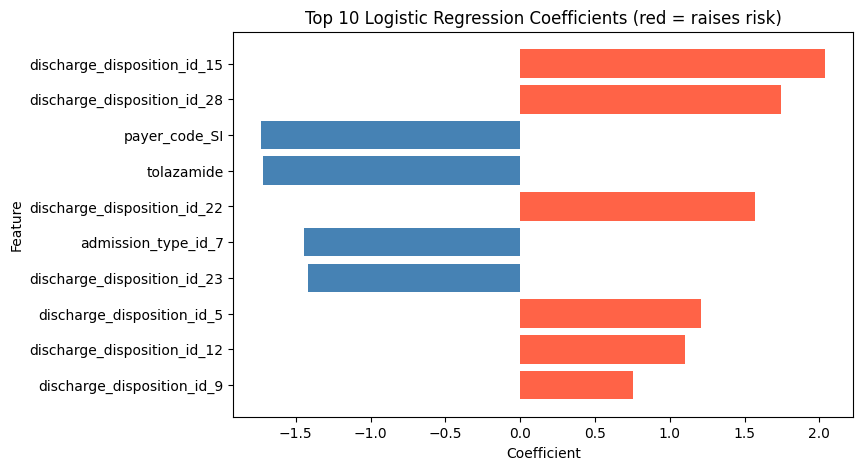

In [12]:
plt.figure(figsize=(8, 5))
colors = ["tomato" if c > 0 else "steelblue" for c in top_log["coefficient"]]
plt.barh(top_log["feature"], top_log["coefficient"], color=colors)
plt.gca().invert_yaxis()     # biggest at the top
plt.title("Top 10 Logistic Regression Coefficients (red = raises risk)")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.show()

**Careful reading:** most of the biggest coefficients belong to **very rare categories**. For example, discharge code 15 (swing bed) has 40 patients, 28 (psychiatric hospital) 90, `payer_code_SI` 37, `tolazamide` 30, and discharge code 12 only 2. With so few patients, one or two readmissions push the coefficient far up or down, so these values are **unstable** and should not be read as the main drivers.

The more reliable signals are the categories with many patients: discharge to a **rehab facility (22, 1,409 patients, 26.33% readmitted)** and to **another inpatient institution (5, 913 patients, 20.59%)**. Both raise risk.

To compare the numeric features fairly (they are all scaled, so 1 unit = 1 standard deviation), here are their coefficients:

In [13]:
numeric_features = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
                    "total_visits", "age_mid", "num_active_meds", "num_med_changes"]

coef.loc[coef["feature"].isin(numeric_features), ["feature", "coefficient"]].sort_values("coefficient", ascending=False).round(3)

,feature,coefficient
7,number_inpatient,0.172
8,number_diagnoses,0.087
33,age_mid,0.076
32,total_visits,0.064
1,time_in_hospital,0.063
6,number_emergency,0.058
35,num_med_changes,0.039
4,num_medications,0.022
2,num_lab_procedures,0.013
3,num_procedures,-0.008


**What we see:** among numeric features, **`number_inpatient` raises risk the most** (+0.172), then `number_diagnoses`, `age_mid`, `total_visits` and `time_in_hospital`. This matches the EDA. `num_active_meds` is negative (-0.286), but it is built from the 21 medicine columns that are also in the model, so its coefficient is mixed up with theirs (multicollinearity) and should not be read on its own.

### Decision Tree feature importance
Importance = how much each feature helped the tree split patients into purer groups (all values add up to 1).

In [14]:
importance = pd.DataFrame({"feature": X.columns, "importance": tree_model.feature_importances_})

top_tree = importance.sort_values("importance", ascending=False).head(10)
top_tree.round(4)

,feature,importance
7,number_inpatient,0.3192
110,discharge_disposition_id_22,0.2206
116,discharge_disposition_id_3,0.1707
118,discharge_disposition_id_5,0.0908
1,time_in_hospital,0.0889
47,payer_code_MC,0.0268
109,discharge_disposition_id_2,0.0184
4,num_medications,0.0112
79,diag_1_group_Respiratory,0.0101
46,payer_code_HM,0.0096


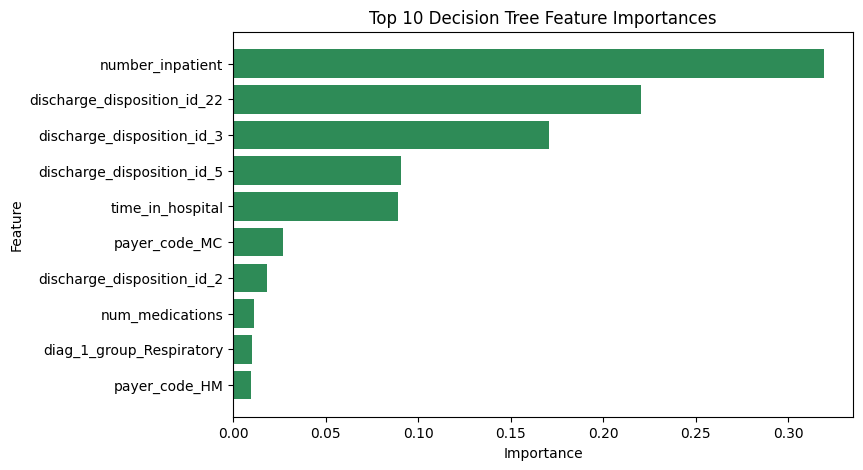

In [15]:
plt.figure(figsize=(8, 5))
plt.barh(top_tree["feature"], top_tree["importance"], color="seagreen")
plt.gca().invert_yaxis()
plt.title("Top 10 Decision Tree Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

**What we see:** the tree agrees with the EDA. **`number_inpatient` (prior inpatient visits) is the most important feature** (0.319), followed by discharge to a rehab facility (22), a skilled nursing facility (3), another inpatient institution (5) and `time_in_hospital`. Patients discharged to another care facility are usually sicker, which explains why they come back more often.

## Step 8: Save Results for the Dashboard

In [16]:
# model metrics (one row per model)
results.round(4).to_csv("../data/model_metrics.csv", index=False)

# top 10 features of each model in one table
top_log_out = top_log[["feature", "coefficient"]].rename(columns={"coefficient": "value"})
top_log_out["model"] = "Logistic Regression (coefficient)"
top_tree_out = top_tree.rename(columns={"importance": "value"})
top_tree_out["model"] = "Decision Tree (importance)"

top_features = pd.concat([top_log_out, top_tree_out])[["model", "feature", "value"]].round(4)
top_features.to_csv("../data/top_features.csv", index=False)

print("Saved ../data/model_metrics.csv and ../data/top_features.csv")

Saved ../data/model_metrics.csv and ../data/top_features.csv
